In [1]:
import sys

print(sys.executable)

d:\metropt3-predictive-maintenance\venv\Scripts\python.exe


In [2]:
import pandas as pd
import numpy as np
import sklearn
import seaborn as sns


In [3]:
df=pd.read_csv("D:/metropt3-predictive-maintenance/data/metropt+3+dataset/MetroPT3(AirCompressor).csv")
df.shape

(1516948, 17)

In [4]:
df.head()

,Unnamed: 0,timestamp,TP2,TP3,H1,DV_pressure,Reservoirs,Oil_temperature,Motor_current,COMP,DV_eletric,Towers,MPG,LPS,Pressure_switch,Oil_level,Caudal_impulses
0,0,2020-02-01 00:00:00,-0.012,9.358,9.340,-0.024,9.358,53.600,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
1,10,2020-02-01 00:00:10,-0.014,9.348,9.332,-0.022,9.348,53.675,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
2,20,2020-02-01 00:00:19,-0.012,9.338,9.322,-0.022,9.338,53.600,0.0425,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
3,30,2020-02-01 00:00:29,-0.012,9.328,9.312,-0.022,9.328,53.425,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
4,40,2020-02-01 00:00:39,-0.012,9.318,9.302,-0.022,9.318,53.475,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0


In [5]:
print(df.columns.tolist())

['Unnamed: 0', 'timestamp', 'TP2', 'TP3', 'H1', 'DV_pressure', 'Reservoirs', 'Oil_temperature', 'Motor_current', 'COMP', 'DV_eletric', 'Towers', 'MPG', 'LPS', 'Pressure_switch', 'Oil_level', 'Caudal_impulses']


In [6]:
df.dtypes

Unnamed: 0           int64
timestamp              str
TP2                float64
TP3                float64
H1                 float64
DV_pressure        float64
Reservoirs         float64
Oil_temperature    float64
Motor_current      float64
COMP               float64
DV_eletric         float64
Towers             float64
MPG                float64
LPS                float64
Pressure_switch    float64
Oil_level          float64
Caudal_impulses    float64
dtype: object

In [7]:
df.isnull().sum()

Unnamed: 0         0
timestamp          0
TP2                0
TP3                0
H1                 0
DV_pressure        0
Reservoirs         0
Oil_temperature    0
Motor_current      0
COMP               0
DV_eletric         0
Towers             0
MPG                0
LPS                0
Pressure_switch    0
Oil_level          0
Caudal_impulses    0
dtype: int64

In [8]:
print(df["timestamp"].iloc[1])
print(df["timestamp"].iloc[-1])
print("\n Number of unique of timestamp",df["timestamp"].nunique())
print("Number of rows",len(df))

2020-02-01 00:00:10
2020-09-01 03:59:50

 Number of unique of timestamp 1516948
Number of rows 1516948


In [9]:
timestamp=pd.to_datetime(df["timestamp"])
time_diff=timestamp.diff()
print(time_diff.value_counts().head())

timestamp
0 days 00:00:10    1337521
0 days 00:00:09     128277
0 days 00:00:12      38321
0 days 00:00:13       7988
0 days 00:00:11       4471
Name: count, dtype: int64


In [10]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,1516948.0,7.584735e+06,4.379053e+06,0.000,3792367.500,7584735.000,1.137710e+07,1.516947e+07
TP2,1516948.0,1.367826e+00,3.250930e+00,-0.032,-0.014,-0.012,-1.000000e-02,1.067600e+01
TP3,1516948.0,8.984611e+00,6.390951e-01,0.730,8.492,8.960,9.492000e+00,1.030200e+01
H1,1516948.0,7.568155e+00,3.333200e+00,-0.036,8.254,8.784,9.374000e+00,1.028800e+01
DV_pressure,1516948.0,5.595619e-02,3.824015e-01,-0.032,-0.022,-0.020,-1.800000e-02,9.844000e+00
Reservoirs,1516948.0,8.985233e+00,6.383070e-01,0.712,8.494,8.960,9.492000e+00,1.030000e+01
Oil_temperature,1516948.0,6.264418e+01,6.516261e+00,15.400,57.775,62.700,6.725000e+01,8.905000e+01
Motor_current,1516948.0,2.050171e+00,2.302053e+00,0.020,0.040,0.045,3.807500e+00,9.295000e+00
COMP,1516948.0,8.369568e-01,3.694052e-01,0.000,1.000,1.000,1.000000e+00,1.000000e+00
DV_eletric,1516948.0,1.606106e-01,3.671716e-01,0.000,0.000,0.000,0.000000e+00,1.000000e+00


In [11]:
import matplotlib.pyplot as plt

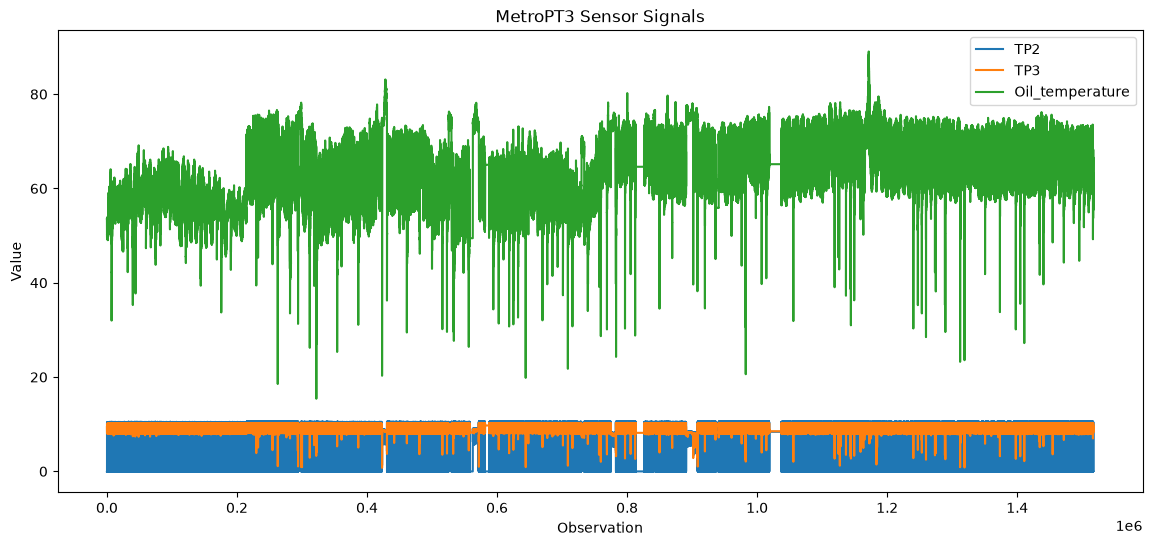

In [12]:
plt.figure(figsize=(14,6))
plt.plot(df["TP2"],label="TP2")
plt.plot(df["TP3"],label="TP3")
plt.plot(df["Oil_temperature"],label="Oil_temperature")

plt.xlabel("Observation")
plt.ylabel("Value")
plt.title("MetroPT3 Sensor Signals")
plt.legend()
plt.show()

In [13]:
binary_cols = [
    "COMP",
    "DV_eletric",
    "Towers",
    "MPG",
    "LPS",
    "Pressure_switch",
    "Oil_level",
    "Caudal_impulses"
]

print(df[binary_cols].mean().sort_values())

LPS                0.003420
DV_eletric         0.160611
MPG                0.832664
COMP               0.836957
Oil_level          0.904156
Towers             0.919848
Caudal_impulses    0.937107
Pressure_switch    0.991437
dtype: float64


d:\metropt3-predictive-maintenance\venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


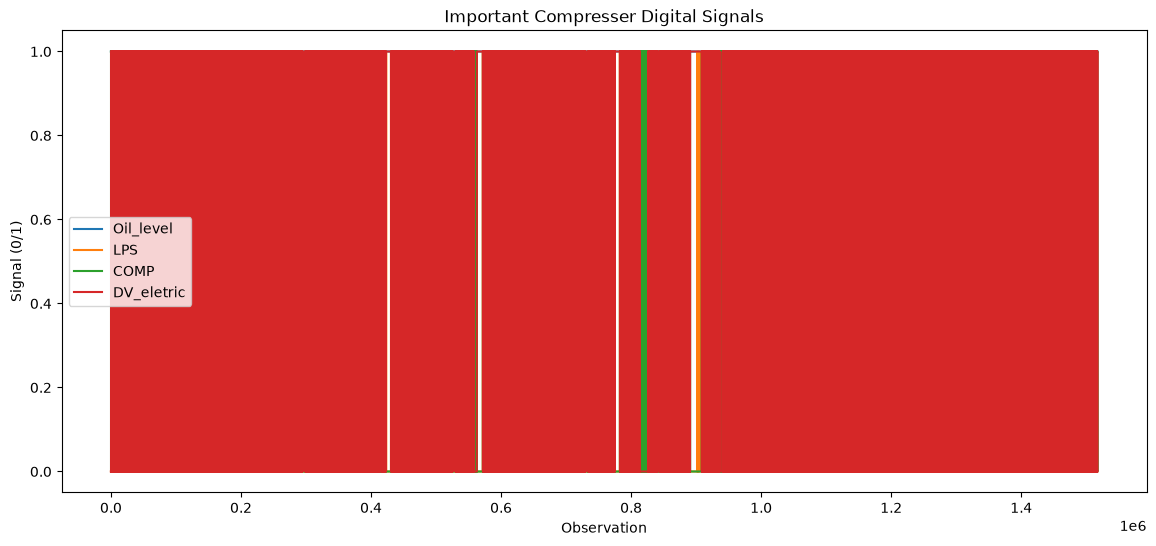

In [14]:
plt.figure(figsize=(14,6))

plt.plot(df["Oil_level"],label="Oil_level")
plt.plot(df["LPS"],label="LPS")
plt.plot(df["COMP"],label="COMP")
plt.plot(df["DV_eletric"],label="DV_eletric")

plt.xlabel("Observation")
plt.ylabel("Signal (0/1)")
plt.title("Important Compresser Digital Signals")

plt.legend()
plt.show()

In [15]:
digital_cols=[
    "Oil_level",
    "LPS",
    "COMP",
    "DV_eletric"
]

for col in digital_cols:
    print(f"\n{col}")
    print(df[col].value_counts(normalize=True).sort_index())



Oil_level
Oil_level
0.0    0.095844
1.0    0.904156
Name: proportion, dtype: float64

LPS
LPS
0.0    0.99658
1.0    0.00342
Name: proportion, dtype: float64

COMP
COMP
0.0    0.163043
1.0    0.836957
Name: proportion, dtype: float64

DV_eletric
DV_eletric
0.0    0.839389
1.0    0.160611
Name: proportion, dtype: float64


In [16]:
continuous_cols = [
    "TP2",
    "TP3",
    "H1",
    "DV_pressure",
    "Reservoirs",
    "Oil_temperature",
    "Motor_current"
]

df[continuous_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
TP2,1516948.0,1.367826,3.250930,-0.032,-0.014,-0.012,-0.0100,10.676
TP3,1516948.0,8.984611,0.639095,0.730,8.492,8.960,9.4920,10.302
H1,1516948.0,7.568155,3.333200,-0.036,8.254,8.784,9.3740,10.288
DV_pressure,1516948.0,0.055956,0.382402,-0.032,-0.022,-0.020,-0.0180,9.844
Reservoirs,1516948.0,8.985233,0.638307,0.712,8.494,8.960,9.4920,10.300
Oil_temperature,1516948.0,62.644182,6.516261,15.400,57.775,62.700,67.2500,89.050
Motor_current,1516948.0,2.050171,2.302053,0.020,0.040,0.045,3.8075,9.295


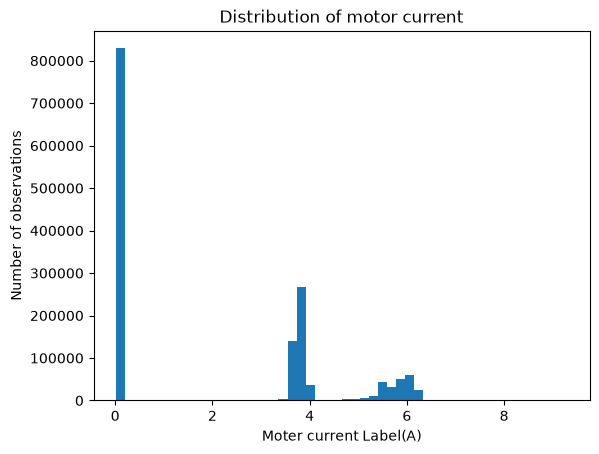

In [17]:
plt.figure()

plt.hist(df["Motor_current"],bins=50)

plt.xlabel("Moter current Label(A)")
plt.ylabel("Number of observations")

plt.title("Distribution of motor current")

plt.show()

In [18]:
current_range=pd.cut(
    df["Motor_current"],
    bins=[0,0.2,3.5,4.2,4.8,6.5,10],
    include_lowest=True
)

current_counts=current_range.value_counts().sort_index()

print(current_counts)

Motor_current
(-0.001, 0.2]    828661
(0.2, 3.5]         1252
(3.5, 4.2]       447012
(4.2, 4.8]         4961
(4.8, 6.5]       234917
(6.5, 10.0]         145
Name: count, dtype: int64


In [19]:
from sklearn.preprocessing import StandardScaler
cluster_feature=[
    "TP2",
    "TP3",
    "H1",
    "DV_pressure",
    "Reservoirs",
    "Oil_temperature",
    "Motor_current"
    ]


X_cluster=df[cluster_feature]
scaler=StandardScaler()
X_scaled=scaler.fit_transform(X_cluster)
print(X_scaled)

[[-0.42444056  0.58424705  0.53157504 ...  0.58399274 -1.38794081
  -0.873208  ]
 [-0.42505577  0.56859993  0.52917494 ...  0.56832629 -1.37643114
  -0.873208  ]
 [-0.42444056  0.5529528   0.52617482 ...  0.55265985 -1.38794081
  -0.87212202]
 ...
 [-0.42505577 -0.14803859  0.39236941 ... -0.14606368 -0.46716709
  -0.87212202]
 [-0.42444056 -0.16994457  0.38876926 ... -0.1679967  -0.47484021
  -0.87103603]
 [-0.42505577 -0.19497997  0.38396907 ... -0.18992973 -0.48634988
  -0.87212202]]


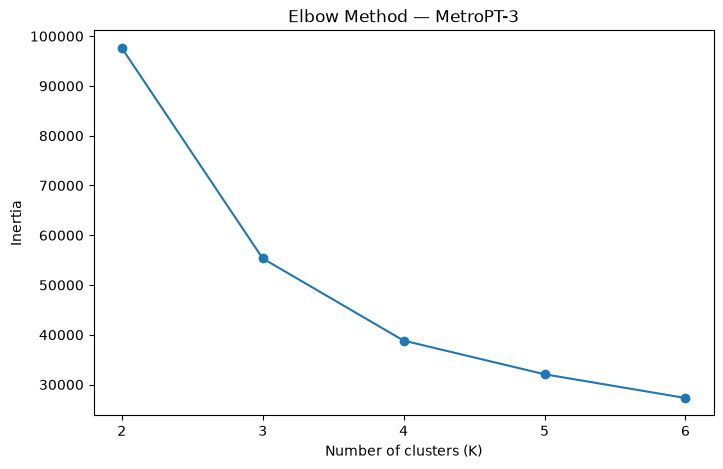

In [20]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

# Random sample of 20,000 observations
X_sample = X_scaled[::75]

inertias = []
k_values = range(2, 7)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=3
    )
    model.fit(X_sample)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, marker="o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method — MetroPT-3")
plt.xticks(list(k_values))
plt.show()

In [21]:
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=3
)

sample_labels = kmeans.fit_predict(X_sample)

score = silhouette_score(
    X_sample,
    sample_labels,
    sample_size=5000,
    random_state=42
)

print("K = 3")
print("Silhouette Score:", round(score, 4))

K = 3
Silhouette Score: 0.4934


In [22]:
# Fit K-Means on the full scaled dataset
final_kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=3
)

df["cluster"] = final_kmeans.fit_predict(X_scaled)

# Count observations in each cluster
print("Cluster sizes:")
print(df["cluster"].value_counts().sort_index())

# Compare average sensor readings by cluster
cluster_profiles = df.groupby("cluster")[cluster_feature].mean().round(3)

print("\nCluster profiles:")
print(cluster_profiles)


Cluster sizes:
cluster
0    465244
1    235364
2    816340
Name: count, dtype: int64

Cluster profiles:
           TP2    TP3     H1  DV_pressure  Reservoirs  Oil_temperature  \
cluster                                                                  
0       -0.007  9.616  9.596       -0.016       9.616           66.829   
1        8.835  8.909  0.025        0.464       8.908           66.593   
2       -0.002  8.647  8.587       -0.020       8.648           59.121   

         Motor_current  
cluster                 
0                3.560  
1                5.790  
2                0.111  


In [23]:
# Convert timestamp strings into datetime values
df["timestamp"] = pd.to_datetime(df["timestamp"])

# Check the time coverage
print("Start:", df["timestamp"].min())
print("End:", df["timestamp"].max())

# Check whether timestamps converted correctly
print("Missing timestamps:", df["timestamp"].isna().sum())

Start: 2020-02-01 00:00:00
End: 2020-09-01 03:59:50
Missing timestamps: 0


In [24]:
failure_windows = [
    {
        "start": "2020-04-18 00:00:00",
        "end": "2020-04-18 23:59:00",
        "event": "Air leak / high stress"
    },
    {
        "start": "2020-05-29 23:30:00",
        "end": "2020-05-30 06:00:00",
        "event": "Air leak / high stress"
    },
    {
        "start": "2020-06-05 10:00:00",
        "end": "2020-06-07 14:30:00",
        "event": "Air leak / high stress"
    },
    {
        "start": "2020-07-15 14:30:00",
        "end": "2020-07-15 19:00:00",
        "event": "Air leak / high stress"
    }
]

for window in failure_windows:
    print(window)

{'start': '2020-04-18 00:00:00', 'end': '2020-04-18 23:59:00', 'event': 'Air leak / high stress'}
{'start': '2020-05-29 23:30:00', 'end': '2020-05-30 06:00:00', 'event': 'Air leak / high stress'}
{'start': '2020-06-05 10:00:00', 'end': '2020-06-07 14:30:00', 'event': 'Air leak / high stress'}
{'start': '2020-07-15 14:30:00', 'end': '2020-07-15 19:00:00', 'event': 'Air leak / high stress'}


In [25]:
for window in failure_windows:
    start = pd.Timestamp(window["start"])
    end = pd.Timestamp(window["end"])

    mask = df["timestamp"].between(start, end, inclusive="both")
    count = mask.sum()

    print(f'{window["event"]}')
    print(f'  Window: {start} to {end}')
    print(f'  Observations: {count:,}\n')

Air leak / high stress
  Window: 2020-04-18 00:00:00 to 2020-04-18 23:59:00
  Observations: 8,657

Air leak / high stress
  Window: 2020-05-29 23:30:00 to 2020-05-30 06:00:00
  Observations: 2,360

Air leak / high stress
  Window: 2020-06-05 10:00:00 to 2020-06-07 14:30:00
  Observations: 17,315

Air leak / high stress
  Window: 2020-07-15 14:30:00 to 2020-07-15 19:00:00
  Observations: 1,622



In [26]:
continuous_cols = [
    "TP2", "TP3", "H1", "DV_pressure",
    "Reservoirs", "Oil_temperature", "Motor_current"
]

failure_mask = pd.Series(False, index=df.index)

for window in failure_windows:
    start = pd.Timestamp(window["start"])
    end = pd.Timestamp(window["end"])

    failure_mask |= df["timestamp"].between(start, end)

print("Failure-window observations:", failure_mask.sum())
print("Other observations:", (~failure_mask).sum())

comparison = pd.DataFrame({
    "Failure window mean": df.loc[failure_mask, continuous_cols].mean(),
    "Other periods mean": df.loc[~failure_mask, continuous_cols].mean()
}).round(3)

print("\nSensor comparison:")
print(comparison)

Failure-window observations: 29954
Other observations: 1486994

Sensor comparison:
                 Failure window mean  Other periods mean
TP2                            8.115               1.232
TP3                            8.288               8.999
H1                             0.038               7.720
DV_pressure                    1.860               0.020
Reservoirs                     8.290               8.999
Oil_temperature               75.598              62.383
Motor_current                  5.532               1.980


In [27]:
failure_percentage = failure_mask.mean() * 100

print(f"Failure-window share: {failure_percentage:.2f}%")
print("Failure labels:", int(failure_mask.sum()))
print("Other labels:", int((~failure_mask).sum()))

Failure-window share: 1.97%
Failure labels: 29954
Other labels: 1486994


In [28]:

from sklearn.model_selection import train_test_split

# Provisional labels based on documented failure windows
df["failure_window"] = failure_mask.astype(int)

# Keep observations in chronological order
df = df.sort_values("timestamp").reset_index(drop=True)

# Use earlier 80% for training and later 20% for testing
split_idx = int(len(df) * 0.8)

train_df = df.iloc[:split_idx].copy()
test_df = df.iloc[split_idx:].copy()

print("Train period:", train_df["timestamp"].min(), "to", train_df["timestamp"].max())
print("Test period:", test_df["timestamp"].min(), "to", test_df["timestamp"].max())

print("\nTraining labels:")
print(train_df["failure_window"].value_counts())

print("\nTesting labels:")
print(test_df["failure_window"].value_counts())


Train period: 2020-02-01 00:00:00 to 2020-07-20 15:58:34
Test period: 2020-07-20 15:58:44 to 2020-09-01 03:59:50

Training labels:
failure_window
0    1183604
1      29954
Name: count, dtype: int64

Testing labels:
failure_window
0    303390
Name: count, dtype: int64


In [32]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import pandas as pd

# Sensor features used for clustering
features = [
    "TP2", "TP3", "H1", "DV_pressure",
    "Reservoirs", "Oil_temperature", "Motor_current"
]

# Fit scaler only on earlier training period
scaler_test = StandardScaler()
X_train_scaled = scaler_test.fit_transform(train_df[features])

# Fit K-Means only on training data
kmeans_test = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=3
)
train_clusters = kmeans_test.fit_predict(X_train_scaled)

# Transform later unseen data using the same scaler
X_test_scaled = scaler_test.transform(test_df[features])

# Assign clusters to unseen test observations
test_clusters = kmeans_test.predict(X_test_scaled)

# Compare cluster distribution
print("Training cluster distribution:")
print(pd.Series(train_clusters).value_counts().sort_index())

print("\nUnseen test cluster distribution:")
print(pd.Series(test_clusters).value_counts().sort_index())

print("\nTest period:")
print(test_df["timestamp"].min(), "to", test_df["timestamp"].max())

Training cluster distribution:
0    688899
1    457588
2     67071
Name: count, dtype: int64

Unseen test cluster distribution:
0    159805
1    142973
2       612
Name: count, dtype: int64

Test period:
2020-07-20 15:58:44 to 2020-09-01 03:59:50


In [33]:
# Attach cluster assignments to each period
train_clustered = train_df.copy()
test_clustered = test_df.copy()

train_clustered["cluster"] = train_clusters
test_clustered["cluster"] = test_clusters

features = [
    "TP2", "TP3", "H1", "DV_pressure",
    "Reservoirs", "Oil_temperature", "Motor_current"
]

print("TRAINING SENSOR PROFILES")
display(
    train_clustered.groupby("cluster")[features]
    .mean()
    .round(3)
)

print("\nUNSEEN TEST SENSOR PROFILES")
display(
    test_clustered.groupby("cluster")[features]
    .mean()
    .round(3)
)

TRAINING SENSOR PROFILES


,TP2,TP3,H1,DV_pressure,Reservoirs,Oil_temperature,Motor_current
cluster,,,,,,,
0,0.039,8.675,8.553,-0.021,8.676,58.450,0.147
1,2.537,9.497,6.961,-0.014,9.497,65.467,4.356
2,8.236,8.416,0.109,1.628,8.417,74.364,5.578



UNSEEN TEST SENSOR PROFILES


,TP2,TP3,H1,DV_pressure,Reservoirs,Oil_temperature,Motor_current
cluster,,,,,,,
0,0.038,8.623,8.474,-0.019,8.625,62.786,0.163
1,2.271,9.505,7.265,-0.017,9.505,68.140,4.284
2,6.920,9.429,4.699,2.783,9.428,68.243,5.099


In [34]:
cluster_2_test = test_clustered.loc[
    test_clustered["cluster"] == 2
].copy()

print("Cluster 2 observations:", len(cluster_2_test))
print("First occurrence:", cluster_2_test["timestamp"].min())
print("Last occurrence:", cluster_2_test["timestamp"].max())

print("\nObservations per day:")
display(
    cluster_2_test
    .set_index("timestamp")
    .resample("D")
    .size()
    .loc[lambda counts: counts > 0]
)

Cluster 2 observations: 612
First occurrence: 2020-07-20 16:45:18
Last occurrence: 2020-09-01 03:23:29

Observations per day:


timestamp
2020-07-20     3
2020-07-21     9
2020-07-22    11
2020-07-23    17
2020-07-24    11
2020-07-25    10
2020-07-26     8
2020-07-27    16
2020-07-28    15
2020-07-29    10
2020-07-30    22
2020-07-31     7
2020-08-01    25
2020-08-02    14
2020-08-03     3
2020-08-05     5
2020-08-06     5
2020-08-07    11
2020-08-08    16
2020-08-09    18
2020-08-10    28
2020-08-11    13
2020-08-12     9
2020-08-13    14
2020-08-14    12
2020-08-15    14
2020-08-16     4
2020-08-17     7
2020-08-18    16
2020-08-19    39
2020-08-20    17
2020-08-21    26
2020-08-22    19
2020-08-23    23
2020-08-24    22
2020-08-25    13
2020-08-26    10
2020-08-27    16
2020-08-28    20
2020-08-29    22
2020-08-30     9
2020-08-31    22
2020-09-01     1
dtype: int64

In [35]:
print("Training cluster percentages:")
display(
    (train_clustered["cluster"].value_counts(normalize=True)
     .sort_index() * 100).round(3)
)

print("\nUnseen test cluster percentages:")
display(
    (test_clustered["cluster"].value_counts(normalize=True)
     .sort_index() * 100).round(3)
)

Training cluster percentages:


cluster
0    56.767
1    37.706
2     5.527
Name: proportion, dtype: float64


Unseen test cluster percentages:


cluster
0    52.673
1    47.125
2     0.202
Name: proportion, dtype: float64

In [29]:

import pandas as pd

print("Cluster counts by failure-window label:")
print(pd.crosstab(df["cluster"], df["failure_window"]))

print("\nCluster distribution within each label (%):")
cluster_distribution = pd.crosstab(
    df["cluster"],
    df["failure_window"],
    normalize="columns"
).mul(100).round(2)

print(cluster_distribution)


Cluster counts by failure-window label:
failure_window       0      1
cluster                      
0               465183     61
1               205585  29779
2               816226    114

Cluster distribution within each label (%):
failure_window      0      1
cluster                     
0               31.28   0.20
1               13.83  99.42
2               54.89   0.38


In [30]:

from pathlib import Path

# Create the metrics folder if it does not exist
metrics_dir = Path("../results/metrics")
metrics_dir.mkdir(parents=True, exist_ok=True)

# 1. Save cluster distribution by failure-window label
cluster_counts = pd.crosstab(
    df["cluster"],
    df["failure_window"]
)

cluster_percentages = pd.crosstab(
    df["cluster"],
    df["failure_window"],
    normalize="columns"
).mul(100).round(2)

cluster_counts.to_csv(
    metrics_dir / "cluster_counts_by_failure_window.csv"
)

cluster_percentages.to_csv(
    metrics_dir / "cluster_percentages_by_failure_window.csv"
)

# 2. Save sensor mean comparison
sensor_comparison = df.groupby("failure_window")[
    continuous_cols
].mean().T

sensor_comparison.columns = [
    "Other_periods_mean",
    "Failure_window_mean"
]

sensor_comparison.to_csv(
    metrics_dir / "sensor_mean_comparison.csv"
)

print("Saved analysis results:")
for file_path in sorted(metrics_dir.glob("*.csv")):
    print(file_path.name)


Saved analysis results:
cluster_counts_by_failure_window.csv
cluster_percentages_by_failure_window.csv
sensor_mean_comparison.csv


In [31]:

from pathlib import Path
import pandas as pd

metrics_dir = Path("../results/metrics")

for filename in [
    "cluster_counts_by_failure_window.csv",
    "cluster_percentages_by_failure_window.csv",
    "sensor_mean_comparison.csv"
]:
    file_path = metrics_dir / filename
    print(f"{filename}: exists={file_path.exists()}")

    if file_path.exists():
        saved_df = pd.read_csv(file_path)
        print("Shape:", saved_df.shape)


cluster_counts_by_failure_window.csv: exists=True
Shape: (3, 3)
cluster_percentages_by_failure_window.csv: exists=True
Shape: (3, 3)
sensor_mean_comparison.csv: exists=True
Shape: (7, 3)
